# Multi-Fidelity Neural Networks
Set of examples to show utility of NN applied to multi-fidelity datasets. Uses Meng and Karniadakis composite NN formulation.

### Initialization
Add the Surrogate Modeling module and setup the notebook

In [1]:
# Boilerplate for automatic reloading of modules on run and connecting to paths of local code.

%load_ext autoreload
%autoreload 2
#%matplotlib widget

import matplotlib.pyplot as plt
import numpy as np

from SurrogateModels import mfsnn

### Function Choice
Set the example function to fit, each has a set high and low fidelity function.

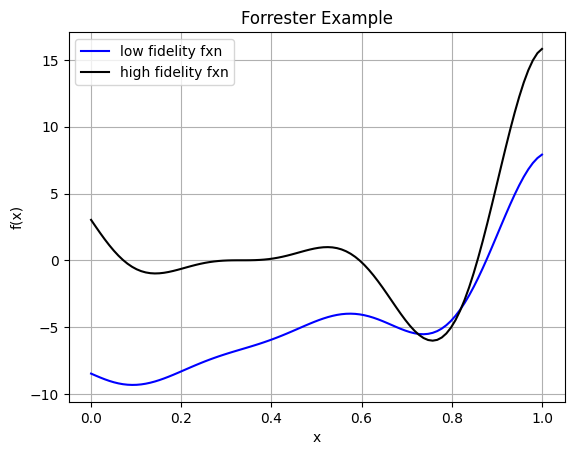

In [2]:
import multi_fidelity_functions
import matplotlib.pyplot as plt

mf_example = multi_fidelity_functions.ForresterExample()
mf_example.plot_functions(name = mf_example.name)
plt.grid()
plt.legend()
plt.show()

### Dataset Generation
Sample the high and low fidelity functions to generate a dataset to fit

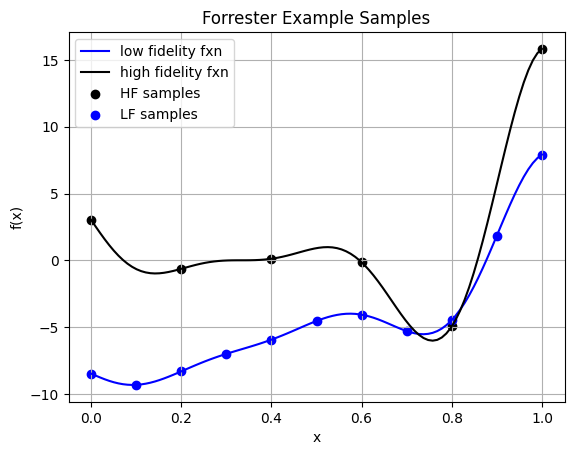

In [3]:
# Define the example function bounds and dimensions here
dim = mf_example.dimensions
xmin = mf_example.bounds[0][0]
xmax = mf_example.bounds[0][1]

n_lf = 11 # number of low fidelity points
n_hf = 6 # number of high fidelity points
n_test = 40 # number of test points

# Generate the analytical functions
hf_fxn = mf_example.high_fidelity
lf_fxn = mf_example.low_fidelity

X_lf = np.linspace(xmin,xmax,n_lf,dtype=np.float32).reshape(-1,1)
y_lf = lf_fxn(X_lf)

X_hf = np.linspace(xmin,xmax,n_hf,dtype=np.float32).reshape(-1,1)
y_hf = hf_fxn(X_hf)

X_test = np.linspace(xmin,xmax,n_test,dtype=np.float32).reshape(-1,1)
y_lf_test = lf_fxn(X_test)
y_hf_test = hf_fxn(X_test)

plot_name = mf_example.name + " Samples"

mf_example.plot_functions(name = plot_name)

plt.figure(plot_name)
plt.title(plot_name)
plt.scatter(X_hf, y_hf, color = "black", label = "HF samples", marker = "o")
plt.scatter(X_lf, y_lf, color = "blue", label = "LF samples", marker = "o")

plt.grid()
plt.legend()
plt.show()

### Function Fit
Fit the dataset using the KAN network

In [6]:
y_test = mf_example.low_fidelity(X_test)
forrester_model = mfsnn.MLPNetwork(X_lf,y_lf,X_test,y_test,hidden_layer_size=[20,20,20])

Epoch: 0   || Train Error: 2.8221139907836914 || Test Error: 0.7054815888404846

Epoch: 1   || Train Error: 2.3012988567352295 || Test Error: 0.5514003038406372

Epoch: 2   || Train Error: 1.259304165840149 || Test Error: 0.2758593261241913

Epoch: 3   || Train Error: 0.8100845813751221 || Test Error: 0.1731853485107422

Epoch: 4   || Train Error: 0.6633004546165466 || Test Error: 0.14260578155517578

Epoch: 5   || Train Error: 0.585040271282196 || Test Error: 0.12714612483978271

Epoch: 6   || Train Error: 0.5349833965301514 || Test Error: 0.1177849993109703

Epoch: 7   || Train Error: 0.49236592650413513 || Test Error: 0.11031504720449448

Epoch: 8   || Train Error: 0.4593621492385864 || Test Error: 0.10497109591960907

Epoch: 9   || Train Error: 0.4261436462402344 || Test Error: 0.09979120641946793

Epoch: 10   || Train Error: 0.27205511927604675 || Test Error: 0.07147087901830673

Epoch: 11   || Train Error: 0.18267259001731873 || Test Error: 0.05117436498403549

Epoch: 12   || Tra

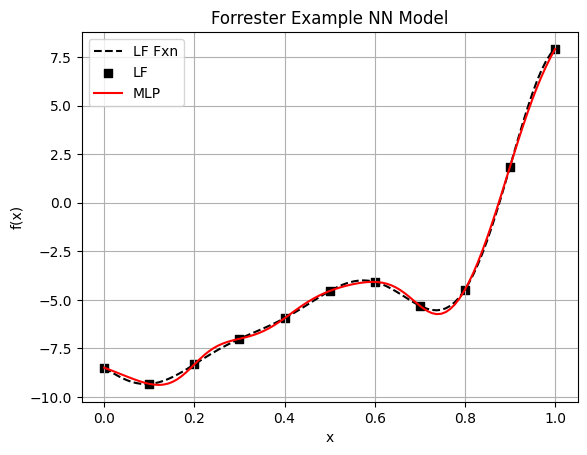

In [10]:
plot_name = mf_example.name + " NN Model"


ax = mf_example.plot_low_fidelity(
    name=plot_name, color="black", label="LF Fxn", linestyle="dashed"
)

ax = forrester_model.plot_data(
    name=plot_name,
    color="black",
    label="LF",
    marker="s",
    ax = ax
)
forrester_model.plot_model(
    mf_example.bounds, name=plot_name, color="red", label="MLP", linestyle="solid",ax=ax
)
plt.legend()
plt.grid()
plt.show()

### MF NN Model
Generate a mf model of the Forrester data using the MF Composite NN formulation

In [ ]:
# MFKAN Model for forrester mf example
forrester_mf_model = mfsnn.MultiFidelityNN(
    X_lf=X_lf,
    y_lf=y_lf,
    X_lf_test=X_test,
    y_lf_test=y_lf_test,
    X_hf=X_hf,
    y_hf=y_hf,
    X_hf_test=X_test,
    y_hf_test=y_hf_test,
    lf_nn_dim=[20, 20, 20],
    hf_nl_nn_dim=[10, 10],
    epochs_lf=200,
    epochs_mf=1000,
    lr_lf=0.001,
    wd_lf=0.000001,
    lr_mf=0.01,
    wd_mf=0.01,
)

Epoch: 0   || Train Error: 2.6974005699157715 || Test Error: 0.6758009195327759

Epoch: 1   || Train Error: 1.981021761894226 || Test Error: 0.47177329659461975

Epoch: 2   || Train Error: 1.155556082725525 || Test Error: 0.2614440619945526

Epoch: 3   || Train Error: 0.8082811236381531 || Test Error: 0.1801496297121048

Epoch: 4   || Train Error: 0.6569534540176392 || Test Error: 0.14624808728694916

Epoch: 5   || Train Error: 0.5777537822723389 || Test Error: 0.12918391823768616

Epoch: 6   || Train Error: 0.5193789601325989 || Test Error: 0.11709006875753403

Epoch: 7   || Train Error: 0.48020684719085693 || Test Error: 0.10948073863983154

Epoch: 8   || Train Error: 0.4518379271030426 || Test Error: 0.10437677055597305

Epoch: 9   || Train Error: 0.425912082195282 || Test Error: 0.09995299577713013

Epoch: 10   || Train Error: 0.31903111934661865 || Test Error: 0.08040256798267365

Epoch: 11   || Train Error: 0.200083389878273 || Test Error: 0.055052775889635086

Epoch: 12   || Tra

KeyboardInterrupt: 

In [ ]:
plot_name = mf_example.name + " MFKAN Model"

ax = forrester_mf_model.plot_model(bounds=mf_example.bounds, name=plot_name)
ax = forrester_mf_model.plot_data(name=plot_name, ax=ax)
ax = mf_example.plot_high_fidelity(name=plot_name,linestyle="dotted", ax=ax)
ax.scatter(X_test, y_hf_test)
y_test_hat = forrester_mf_model.evaluate(X_test)
error = (np.sqrt((y_test_hat - y_hf_test)**2)).mean()
print(error/n_test)
ax.legend()
plt.grid()
plt.show()

In [ ]:
forrester_mf_model.plot_rms_error(mf_example.bounds,mf_example.high_fidelity)

In [ ]:
plt.figure("LF KAN Training Loss")
plt.plot(forrester_mf_model.lf_kan_model.results['train_loss'])
plt.plot(forrester_mf_model.lf_kan_model.results['test_loss'])
plt.legend(['train', 'test'])
plt.ylabel('RMSE')
plt.xlabel('step')
plt.title('LF KAN Error Measure')
plt.yscale('log')

In [ ]:
plt.figure("MF KAN Training Loss")
plt.plot(forrester_mf_model.mf_kan_model.results['train_loss'])
plt.plot(forrester_mf_model.mf_kan_model.results['test_loss'])
plt.legend(['train', 'test'])
plt.ylabel('RMSE')
plt.xlabel('step')
plt.title('LF KAN Error Measure')
plt.yscale('log')

### 2D Examples
Test single and multi-fidelity fits on more complex datasets starting with the Zhang Example 6.

In [ ]:
import multi_fidelity_functions as mff
import matplotlib.pyplot as plt
from SurrogateModels import cokriging, model

n_hf = 4
n_lf = 15
n_samp = 75

mf_2d = mff.ZhangExample6()

bounds = mf_2d.bounds
x1min = bounds[0][0]
x1max = bounds[0][1]
x2min = bounds[1][0]
x2max = bounds[1][1]

x_hf = model.Model.generate_grid_array(x1min, x1max, x2min, x2max, n_hf)
x_lf = model.Model.generate_grid_array(x1min, x1max, x2min, x2max, n_lf)
y_hf = mf_2d.high_fidelity(x_hf)
y_lf = mf_2d.low_fidelity(x_lf)

# take samples for plotting ground truth function
x_samp = model.Model.generate_grid_array(x1min, x1max, x2min, x2max, n_samp)
y_samp_hf = mf_2d.high_fidelity(x_samp)
y_samp_lf = mf_2d.low_fidelity(x_samp)
print(x_samp.shape)

# Set figure size for plots
fig = plt.figure(figsize=(18,12))

# Plot the data
ax = fig.add_subplot(121, projection="3d")

sc = ax.scatter(x_hf[:, 0], x_hf[:, 1],y_hf[:,0], label="hf_data")
sc = ax.scatter(x_lf[:, 0], x_lf[:, 1],y_lf[:,0], label="lf_data")
ax.legend()

#Plot the actual surfaces of the lf and hf functions

X1, X2 = model.Model.generate_grid(x1min, x1max, x2min, x2max, n_samp)
y_samp_hf = y_samp_hf.reshape(n_samp,n_samp)
y_samp_lf = y_samp_lf.reshape(n_samp,n_samp)

ax = fig.add_subplot(122, projection="3d")
ax.plot_surface(X1, X2, y_samp_hf,label="hf fxn")
ax.plot_surface(X1, X2, y_samp_lf,label="lf fxn")
ax.legend()

plt.show()

In [ ]:
zhang_example6_kriging = mfkans.KANModel(
    x_lf,
    y_lf,
    x_samp,
    y_samp_lf,
    spline_order=3,
    width=[2, 4, 1],
    grid=3,
    opt="LBFGS",
    n_iter=50,
)
ax = zhang_example6_kriging.plot_data(name="Zhang Example 6 HF Fit")

ax = zhang_example6_kriging.plot_model(
    mf_2d.bounds,
    name="Zhang Example 6 HF Kriging",
    color="blue",
    label="kriging",
    ax=ax,
    n_samples=30,
)

# X1, X2 = mff.generate_grid(x1min, x1max, x2min, x2max, n_samp)
# y_samp = zhang_example6_kriging.evaluate(x_samp)
# y_samp = y_samp.reshape(n_samp,n_samp)

# ax.plot_surface(X1, X2, y_samp,label="kriging surface")
# ax.legend()
plt.show()